# Clio-Infra at historical borders over MCP

The tools a model would call, in order. Like every stored source this one has no
tools of its own, and the stored-series tools take ids — so a lookup starts at
the catalog.

    series_catalog_concepts → series_catalog_search → timeseries_source_list → timeseries_source_data

The facets that are particular to this source: `polity`, `border_start`,
`border_end`, `relation` (how a series stands to the main site) and, where the
main site carries the same numbers, `modern_country`. The MCP server must be
running.

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
sys.path.append("../")          # notebooks/clio_historical/, for utils
sys.path.append("../../../")    # meida, for mcp_server

from matplotlib import pyplot

from lib import config
from utils import (borders_of, concepts, describe, get_series, search_catalog,
                   stamp_source, to_arrays, break_gaps)

pyplot.style.use(config.glyfish_style)

## What exists

In [2]:
for c in await concepts():
    print(f"  {c['series_count']:4d}  {c['concept']}")

   176  exchange_rates_to_uk_pound
   117  number_of_days_lost_in_labour_disputes
    98  labourers_real_wage


## What the main site does not have

`relation="new"` finds the series with no counterpart on the main site at all.

In [3]:
new = await search_catalog(relation="new", limit=50)
print(f"{new['total']} series the main site lacks:")
for e in new["entries"]:
    print(f"  {e['title']}")

3 series the main site lacks:
  Labourers Real Wage — Falklands (borders 1840–1945)
  Labourers Real Wage — Hong Kong (borders 1860–1945)
  Labourers Real Wage — Yugoslavia (borders 1920–1945)


## Following a polity through its borders

`borders_of` lists every border period a polity has for an indicator. The
Ottoman Empire's exchange rate, fetched period by period and drawn as one
timeline, coloured by the borders in force:

8 border periods, missing []


Text(0.995, 0.005, 'clio_historical/exchange_rates_to_uk_pound/ottoman_{1780_1799, 1800_1819, 1820_1839, 1840_1859, 1860_1879, 1880_1899, 1900_1919, 1920_1945}')

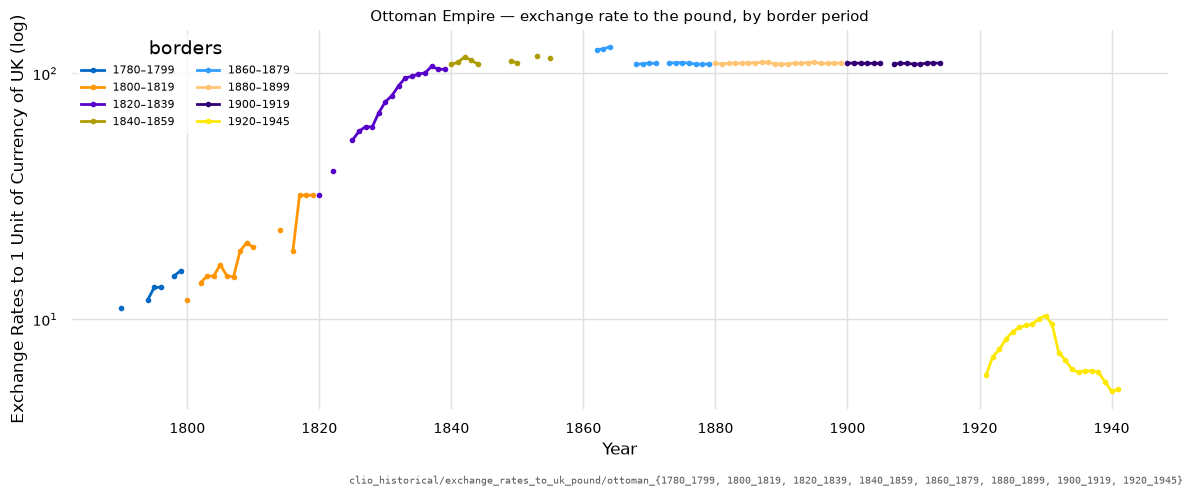

In [4]:
periods = await borders_of("ottoman", "exchange_rates_to_uk_pound")
coverage = await describe([e["retrieval"]["native_id"] for e in periods])
print(f"{coverage['returned']} border periods, missing {coverage['missing']}")
series = [await get_series(e["retrieval"]["native_id"]) for e in periods]

figure, axis = pyplot.subplots(figsize=(12, 5))
for e, s in zip(periods, series):
    years, values = break_gaps(*to_arrays(s))
    axis.plot(years, values, lw=2, marker="o", markersize=3,                     # (x, y)
              label=f"{e['facets']['border_start']}–{e['facets']['border_end']}")
axis.set_yscale("log")
axis.set_ylabel(f"{series[0]['units']} (log)")
axis.set_xlabel("Year")
axis.set_title("Ottoman Empire — exchange rate to the pound, by border period", fontsize=11)
axis.legend(title="borders", fontsize=8, ncol=2, loc="upper left")
figure.tight_layout()
# all eight in one line: the common prefix, then each period
prefix = series[0]['native_id'].rsplit('_', 2)[0]
figure.subplots_adjust(bottom=0.16)
figure.text(0.995, 0.005, f"{prefix}_{{" + ', '.join(s['native_id'].split(prefix + '_')[1] for s in series) + "}",
            ha='right', va='bottom', fontsize=7, family='monospace', alpha=0.65)

The scale is logarithmic because the rate moved an order of magnitude — from
about 11 to the pound in the 1790s to about 110 by the 1840s, then steady until
the First World War.

**The fall in 1920 is a change of unit, not a strengthening.** Before 1914 the
rate is in kuruş (piastres) per pound — about 110, the familiar pre-war figure,
since an Ottoman lira was 100 kuruş and worth a little under a pound. After 1920
it is in lira, about 9 to the pound by the late 1920s — which is roughly 900
kuruş, so the currency had in fact lost most of its value through the war. The
series' unit, "Exchange Rates to 1 Unit of Currency of UK", does not say which
Ottoman or Turkish unit is meant; the magnitudes do.

Every one of these values is also on the main site — filed under Turkey:


In [5]:
under_turkey = await search_catalog(concept="exchange_rates_to_uk_pound", limit=50,
                                    modern_country="turkey")
print(f"{under_turkey['total']} exchange-rate series the main site files under Turkey; polities: "
      f"{sorted({e['facets']['polity'] for e in under_turkey['entries']})}")

9 exchange-rate series the main site files under Turkey; polities: ['ottoman', 'turkey']


For the same data through the Python clients, with the one border difference
drawn against the main site, see [`client.ipynb`](client.ipynb).